# Fault-line DP + Basin Hopping

Three steps beyond merging public notebooks:

1. **Couzo's certified register.** Francisco Couzo keeps exact (rational) packings for n = 1 … 10,000 at
   [github.com/franciscouzo/square-packing](https://github.com/franciscouzo/square-packing) (MIT), many of them
   records above n = 324 that no public notebook had. We convert them and keep each one only if the official metric
   certifies it after a float64 round trip.
2. **Search.** Basin hopping with Evan Daniel's Rust engine from
   [github.com/evand/square-packing](https://github.com/evand/square-packing) (`search/packer`, MIT), started from
   our current packings of the puzzles above 324 that are still plain 0°/45° constructions.
3. **Fault-line gadget DP.** Our rebuild of Chris Deotte's composition: crops of the best packings (including the hop
   results) become gadgets along a fault between two shifted lattices, so one local improvement is reused in many n.

Builds on *Thinking Outside the Grid* (the problem, the float64 trap, the 45° family) and
*Certified Merge of Public Packings* (whose output is the starting point here).

In [1]:
import os, sys, glob, math, shutil, subprocess, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Rectangle
SRC = next(os.path.dirname(p) for p in glob.glob('/kaggle/input/**/hop_search.py', recursive=True) + ['../src/hop_search.py'] if os.path.exists(p))
sys.path.insert(0, SRC)
import metric
from ensemble import side, certify
KAGGLE = os.path.exists('/kaggle/input')
OUT = '/kaggle/working' if KAGGLE else '../submissions'
# starting point: the output of the public 'Certified Merge of Public Packings' notebook (locally: the same file)
BASE = next(p for p in glob.glob('/kaggle/input/**/submission.csv', recursive=True) if 'certified-merge' in p) if KAGGLE     else '../submissions/sub_ens2.csv'
COUZO, HOP = f'{SRC}/couzo.csv' if KAGGLE else '../submissions/couzo.csv', f'{SRC}/hop.csv' if KAGGLE else '../submissions/hop.csv'
BIG = f'{SRC}/couzo_big.csv' if KAGGLE else '../submissions/couzo_big.csv'
def load(path):
    df = pd.read_csv(path)
    return {int(n): g.sort_values('square_id')[['x', 'y', 'angle']].to_numpy(float) for n, g in df.groupby('n') if len(g) == n}
base = load(BASE)
print('starting point:', BASE, f'| side-based total {sum(side(base[n]) / math.sqrt(n) - 1 for n in base):.6f}')

starting point: /kaggle/input/notebooks/alexchilton/certified-merge-of-public-packings-lb-22-5978/submission.csv | side-based total 22.597200


## 1. Couzo's witnesses

Each `.cert` file is an exact packing: the first line is `n side`, then one line per square `x y t` as rationals,
with the rotation stored as `t = tan(θ/2)` so that cos and sin stay rational. Exact packings touch exactly, which the
official metric cannot certify after float64 rounding, so `couzo.py` converts them with 40-digit arithmetic and scales
each packing by 1 + 1e-12 about its centre. Converted file: `couzo.csv` in the starter-kit dataset.

717 witnesses with n <= 1000; smaller box than the starting point at 146 puzzles, total score gain 0.008211 (before certification)


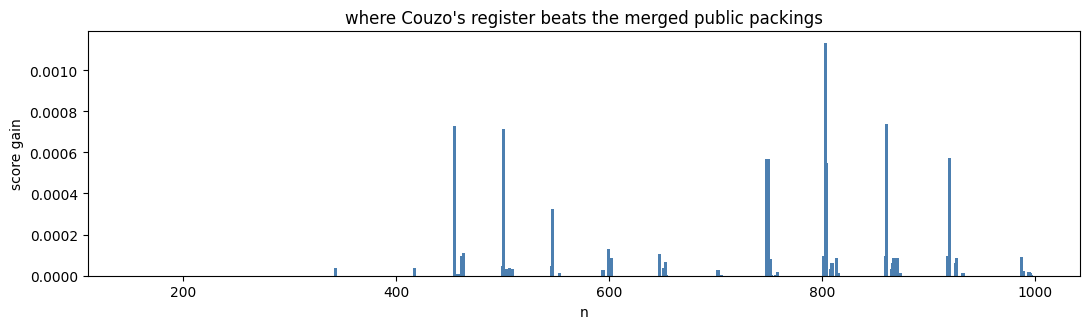

,n,side before,Couzo side,score gain
98,803,28.859651,28.827585,0.001132
110,860,29.849242,29.827585,0.000739
41,455,21.863961,21.848427,0.000728
52,501,22.903779,22.887842,0.000712
123,919,30.844933,30.827585,0.000572
86,749,27.899506,27.884019,0.000566
85,748,27.899495,27.884019,0.000566
99,804,28.899495,28.884019,0.000546


In [2]:
couzo = load(COUZO)
rows = []
for n, sq in couzo.items():
    if n in base and side(sq) < side(base[n]) - 1e-9:
        rows.append((n, side(base[n]), side(sq), (side(base[n]) - side(sq)) / math.sqrt(n)))
imp = pd.DataFrame(rows, columns=['n', 'side before', 'Couzo side', 'score gain'])
print(f'{len(couzo)} witnesses with n <= 1000; smaller box than the starting point at {len(imp)} puzzles, '
      f'total score gain {imp["score gain"].sum():.6f} (before certification)')
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(imp.n, imp['score gain'], width=3, color='#4c7fb0'); ax.set_xlabel('n'); ax.set_ylabel('score gain')
ax.set_title("where Couzo's register beats the merged public packings"); plt.tight_layout(); plt.show()
imp.sort_values('score gain', ascending=False).head(8)

## 2. Basin hopping

`packer hop` keeps the box side fixed and minimises the total overlap (separating-axis penetration, as in the metric)
with L-BFGS. Every step it perturbs a few squares (shift, rotate, swap) and accepts the result by a Metropolis rule.
Whenever the packing becomes overlap-free it **squeezes** the box and sets the next target just below the best side
found, so a run only ever goes down.

Starting points matter: the 0°/45° constructions are rigid and symmetric, and a few minutes of hopping often finds
a slightly tilted, slightly smaller relative. We build the engine here (needs *internet on*) and run a short live
demo; the bigger runs were done offline with the same code (`hop_search.py`), results in `hop.csv`.

In [3]:
if KAGGLE:
    t = time.time()
    sh = lambda c: subprocess.run(c, shell=True, capture_output=True, text=True)
    sh('curl -sSf https://sh.rustup.rs | sh -s -- -y --profile minimal')
    sh('git clone -q --depth 1 --filter=blob:none --sparse https://github.com/evand/square-packing.git /kaggle/working/evand && '
       'cd /kaggle/working/evand && git sparse-checkout set --no-cone /search/packer/src/ /search/packer/Cargo.toml /search/packer/Cargo.lock')
    r = sh('cd /kaggle/working/evand/search/packer && $HOME/.cargo/bin/cargo build --release --bin packer')
    os.environ['PACKER_BIN'] = '/kaggle/working/evand/search/packer/target/release/packer'
    print(r.stderr[-400:], f'built in {time.time() - t:.0f}s')
    assert os.path.exists('/kaggle/working/evand/search/packer/target/release/packer'), 'packer build failed (is internet on?)'
else:
    os.environ['PACKER_BIN'] = os.path.abspath('../external/evand/search/packer/target/release/packer')
os.environ['HOP_WORK'] = os.path.abspath(f'{OUT}/hop_demo'); os.makedirs(os.environ['HOP_WORK'], exist_ok=True)
import hop_search
print('engine:', os.environ['PACKER_BIN'], os.path.exists(os.environ['PACKER_BIN']))

ax(1e-6));
    |                     ----^^^^
    |                     |
    |                     help: remove this `mut`
    |
    = note: `#[warn(unused_mut)]` (part of `#[warn(unused)]`) on by default

    Finished `release` profile [optimized + debuginfo] target(s) in 25.51s
 built in 42s
engine: /kaggle/working/evand/search/packer/target/release/packer True


In [4]:
demo = [494, 845, 903]
cur = {n: base[n] for n in demo}
t = time.time()
from multiprocessing import Pool
with Pool(3) as pool:
    res = pool.map(hop_search.run, [(n, cur[n], 3.0, 1) for n in demo])
for n, L0, L1, why, sec in res:
    print(f'n={n}: start {L0:.6f} -> {L1 if L1 is None else round(L1, 6)}  {why}  ({sec:.0f}s)')
print(f'live demo: {time.time() - t:.0f}s')

n=494: start 22.742641 -> 22.742641  no gain  (180s)
n=845: start 29.591883 -> 29.591883  no gain  (180s)
n=903: start 30.571068 -> 30.571068  no gain  (180s)
live demo: 180s


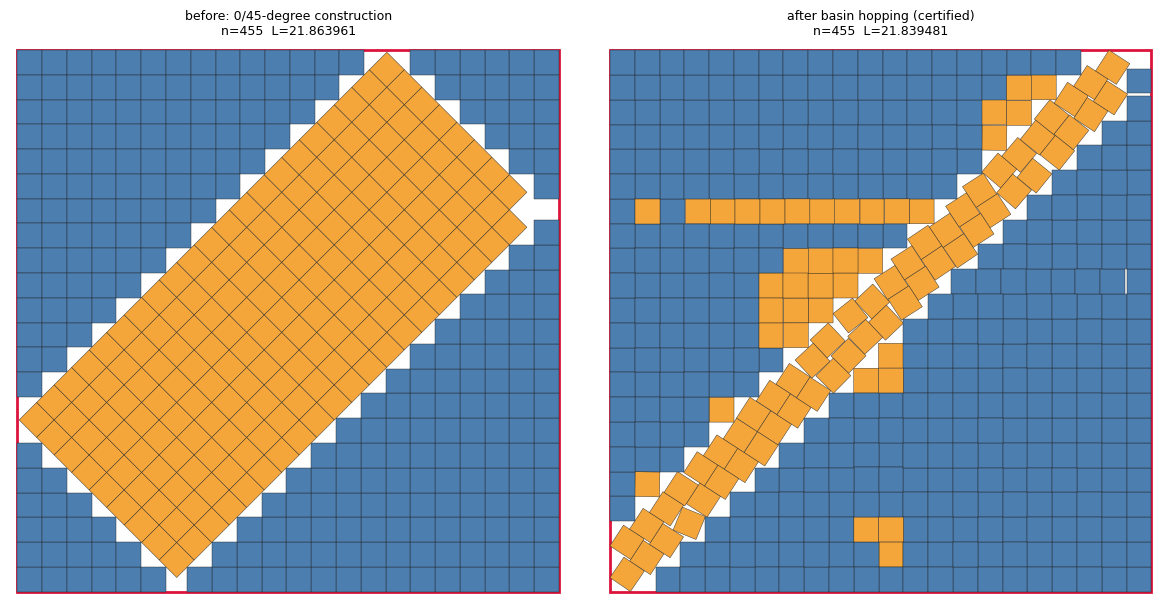

114 puzzles improved by the offline runs


In [5]:
def corners(x, y, a):
    c, s = math.cos(a), math.sin(a)
    return [(x + dx * c - dy * s, y + dx * s + dy * c) for dx, dy in [(.5, .5), (-.5, .5), (-.5, -.5), (.5, -.5)]]
def draw(ax, sq, title):
    pts = [p for q in sq for p in corners(*q)]
    xs, ys = zip(*pts); L = max(max(xs) - min(xs), max(ys) - min(ys))
    ax.add_patch(Rectangle((min(xs), min(ys)), L, L, fill=False, ec='crimson', lw=2))
    for x, y, a in sq:
        tilt = abs(math.sin(2 * a)) > 1e-6
        ax.add_patch(Polygon(corners(x, y, a), fc='#f4a63a' if tilt else '#4c7fb0', ec='#222', lw=.3))
    ax.set_title(f'{title}\nn={len(sq)}  L={L:.6f}', fontsize=9); ax.set_aspect('equal'); ax.axis('off')
    ax.set_xlim(min(xs) - .3, min(xs) + L + .3); ax.set_ylim(min(ys) - .3, min(ys) + L + .3)
hop = load(HOP)
n0 = max(hop, key=lambda n: (side(base[n]) - side(hop[n])) / math.sqrt(n))
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
draw(ax[0], base[n0], 'before: 0/45-degree construction'); draw(ax[1], hop[n0], 'after basin hopping (certified)')
plt.tight_layout(); plt.show()
print(f'{len(hop)} puzzles improved by the offline runs')

## 3. Merge everything

In [6]:
srcs = {'base': BASE, 'couzo': COUZO, 'hop': HOP}
for p in glob.glob('/kaggle/input/**/submission.csv', recursive=True):   # other attached public notebooks' outputs
    if p != BASE and 'starter-kit' not in p:
        srcs[p.split('/')[-2][:40]] = p
for f in glob.glob(f"{os.environ['HOP_WORK']}/[0-9]*.csv"):
    srcs['live_' + os.path.basename(f)] = f
args = [sys.executable, '-u', f'{SRC}/ensemble.py', f'{OUT}/merged.csv'] + [f'{k}={v}' for k, v in srcs.items()]
print(subprocess.run(args, capture_output=True, text=True).stdout)

wrote /kaggle/working/merged.csv: certified total 22.479723; needed 1e-12 dilation: 0
puzzles won by source: {'grid': 457, 'squares-in-squares-multi-gadget-fault-dp': 204, 'base': 193, 'couzo': 109, 'hop': 33, 'squares-in-squares-fresh-records-certifi': 3, 'squares-in-squares-cuda-packing-search': 1}



## 4. Fault-line gadget DP

Idea from Chris Deotte's *multi-gadget fault DP* notebook (his markdown describes it; his notebook ships the packings, not the code,
so `fault_dp.py` is our rebuild). Write n = K² + D. Fill the lower-left of a box with upright unit cells on the integer lattice
and the upper-right with the same lattice shifted by f in x and y. The two "continents" meet along a staircase fault running
down the anti-diagonal. Along the fault sit **gadgets**: w × h blocks that hold w·h + dm squares inside (w+f) × (h+f).
Every gadget adds dm squares; the box side is K + f, with f the largest overhang in the chain.

* **Gadgets are crops.** Take any good packing (ours, Couzo's up to n = 3500, the hop results), under each of its 8 symmetries,
  and for every (w, h, dm) keep the w·h + dm squares that stick out least past w × h: that order statistic is f.
* **Seams.** Two gadgets meet corner to corner (only if the tips cannot collide), or with one lattice column or row between them.
* **DP** over (columns used, rows used, surplus, tip type of the last gadget), minimising the largest f.
  A gadget that basin hopping improved in one puzzle is then reused in every band that can hold it.
* Each composition is certified with the official metric after the float64 round trip before it is used.

pass 0: 09:41:52 [   561s] DONE total certified gain 0.002139 on 52 puzzles
pass 1: 09:52:58 [   504s] DONE total certified gain 0.000219 on 15 puzzles
pass 2: 10:03:00 [   450s] DONE total certified gain 0.000119 on 7 puzzles
(1982s)


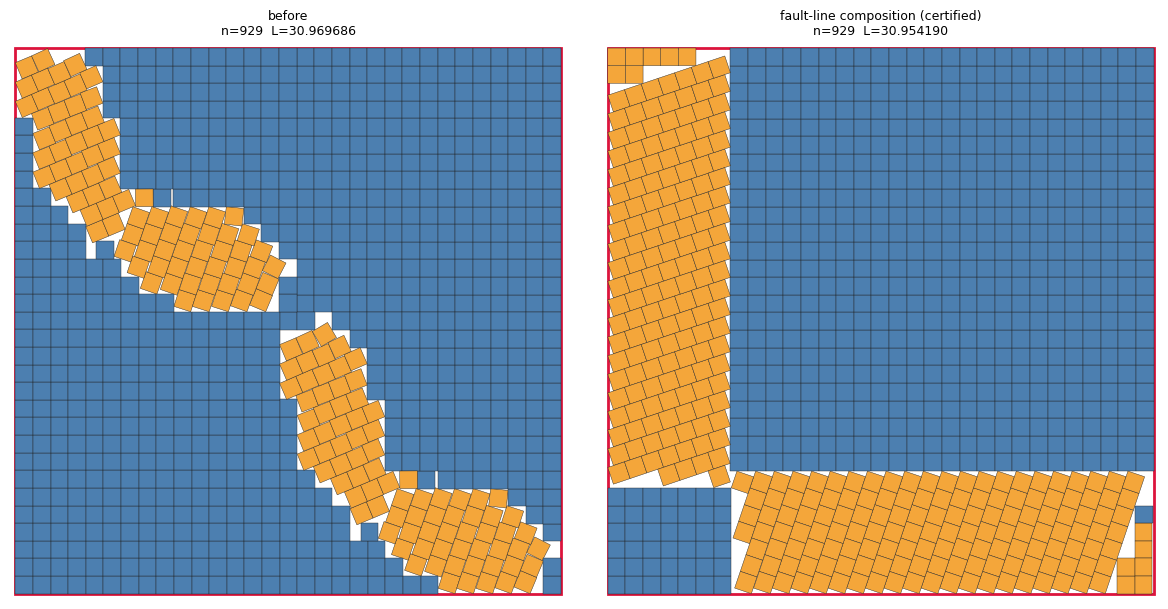

In [7]:
t = time.time()
cur, first, total = f'{OUT}/merged.csv', {}, 0
for p in range(3):          # each pass: DP on the current file (its compositions become donors), merge, closures
    r = subprocess.run([sys.executable, '-u', f'{SRC}/fault_dp.py', cur, f'{OUT}/fault{p}', COUZO, HOP, BIG],
                       capture_output=True, text=True)
    fault = {int(os.path.basename(f)[:-4]): f for f in glob.glob(f'{OUT}/fault{p}/[0-9]*.csv')}
    print(f'pass {p}: ' + next((l for l in r.stdout.splitlines() if 'DONE' in l), r.stderr[-500:]) + f' on {len(fault)} puzzles')
    if p == 0:
        first = fault
    if not fault:
        break
    args = [sys.executable, '-u', f'{SRC}/ensemble.py', f'{OUT}/m{p}.csv', f'cur={cur}'] + [f'fault_{n}={f}' for n, f in fault.items()]
    subprocess.run(args, capture_output=True, text=True)
    subprocess.run([sys.executable, '-u', f'{SRC}/closure.py', f'{OUT}/m{p}.csv', f'{OUT}/c{p}.csv'], capture_output=True, text=True)
    cur = f'{OUT}/c{p}.csv'
print(f'({time.time() - t:.0f}s)')
if first:
    merged = load(f'{OUT}/merged.csv')
    n1 = max(first, key=lambda n: (side(merged[n]) - side(load(first[n])[n])) / math.sqrt(n))
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    draw(ax[0], merged[n1], 'before'); draw(ax[1], load(first[n1])[n1], 'fault-line composition (certified)')
    plt.tight_layout(); plt.show()

## 5. Official score

In [8]:
shutil.copy(cur, f'{OUT}/submission.csv')
t = time.time()
s = pd.read_csv(f'{OUT}/submission.csv').astype(str)
print(f"official metric, full file after float64: {metric.score(pd.DataFrame({'id': range(1000), 'n': range(1, 1001)}), s, 'id'):.6f} ({time.time() - t:.0f}s)")

official metric, full file after float64: 22.477246 (269s)


## 6. What we learned

* **Search rate.** A pilot of 24 construction puzzles × 5 CPU-minutes improved 4 of them, +0.000297 in total:
  about 1.5e-4 score per CPU-hour. Small per run, but there are ~220 such puzzles above n = 324 and nothing else is
  searching them.
* **The grid puzzles are not the target.** 457 puzzles are still the plain grid; for none of them is any smaller box
  known (checked against Couzo's register), and 144 are proven optimal (n = k², k² − 1 … k² − 4). They add the same
  ~7.36 to every team's score.
* **Composition multiplies search.** The fault DP turned hop results on single puzzles (e.g. n = 372, 451) into gadgets
  for larger puzzles: 47 more puzzles improved, +0.0021, from donors we already had. Re-running it on its own output
  gives +0.0002, then +0.0001: it converges in about three passes.
* **What decides the leaderboard**: syncing new public records quickly (ties go to the earliest submission) and
  search on the non-grid puzzles above 324.

*Credits: Chris Deotte (the fault-line gadget idea), Francisco Couzo (certified register), Evan Daniel and contributors (evand/square-packing, packer engine),
David Ellsworth (records, enumerator), Erich Friedman's survey, and the public notebooks merged in the starting point.
If this helped, an upvote is appreciated.*